# 04 Outlier Analysis

This notebook reuses the shared dataset loader from the earlier exploration notebooks and focuses only on the detectors selected for the current analysis stage.

The methods currently applied are:

- LOF
- Angle-Based Outlier Detection
- Mahalanobis distance
- Classification-based confidence

The analysis is run on the full dataset and on each class separately, using only the accelerometer columns (`x1..z4`). Each result also includes a compact PCA-based visualization that highlights the outliers against the normal points.

In [ ]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def find_project_root():
    base_dir = Path.cwd()
    for candidate in [base_dir, base_dir.parent, base_dir.parent.parent]:
        if (candidate / 'JUPYTER_NOTEBOOKS').exists():
            return candidate
    return base_dir


base_dir = find_project_root()
jupyter_notebooks_dir = base_dir / 'JUPYTER_NOTEBOOKS'
if str(jupyter_notebooks_dir) not in sys.path:
    sys.path.insert(0, str(jupyter_notebooks_dir))

from shared.data import load_exploration_data

try:
    from pyod.models.abod import ABOD
    PYOD_AVAILABLE = True
except Exception:
    PYOD_AVAILABLE = False


df, data_path, malformed_z4_mask, malformed_z4_rows = load_exploration_data()

class_col = 'class'
user_col = 'user'
sensor_cols = ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']
analysis_numeric_features = sensor_cols.copy()
model_feature_cols = sensor_cols.copy()
class_names = sorted(df[class_col].astype(str).unique().tolist())

print(f'Loaded dataset from: {data_path}')
print(f'Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
print('Classes:', class_names)
print('Sensor columns used for outlier analysis:', sensor_cols)
if PYOD_AVAILABLE:
    print('Angle-Based Outlier Detection is enabled.')
else:
    print('Angle-Based Outlier Detection is not available in this environment; only LOF, Mahalanobis, and classification-based scoring will run.')


def prepare_numeric_matrix(frame: pd.DataFrame, feature_cols: list[str]):
    numeric_frame = frame[feature_cols].copy()
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    return numeric_pipeline.fit_transform(numeric_frame)



Loaded dataset from: C:\Users\matte\Desktop\DMML_Wearable_Body_Postures\SOURCES\dataset.csv
Dataset shape: 165,633 rows x 19 columns
Classes: ['sitting', 'sittingdown', 'standing', 'standingup', 'walking']
Sensor columns used for outlier analysis: ['x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4']
Angle-Based Outlier Detection is not available in this environment; only LOF, Mahalanobis, and classification-based scoring will run.



=== Overall dataset outlier analysis ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,1657,1.0
1,LOF,1657,1.0
2,Mahalanobis,1657,1.0


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
59221,59221,wallace,sittingdown,3,True,1.000000,12.692344,856.796329
151736,151736,wallace,walking,3,True,1.000000,3.035847,214.462697
115263,115263,katia,standingup,3,True,1.000000,2.617226,158.888771
164664,164664,jose_carlos,walking,3,True,1.000000,4.510722,768.941871
115264,115264,katia,standingup,3,True,1.000000,2.882861,160.276999
151735,151735,wallace,walking,3,True,1.000000,2.523366,98.403868
102974,102974,wallace,standing,3,True,0.999994,2.520120,129.659506
102972,102972,wallace,standing,3,True,0.999991,2.586894,133.385778
102973,102973,wallace,standing,3,True,0.999990,2.577699,132.836560
102975,102975,wallace,standing,3,True,0.999990,2.621239,125.281690


Consensus rows flagged by at least 2 methods: 185


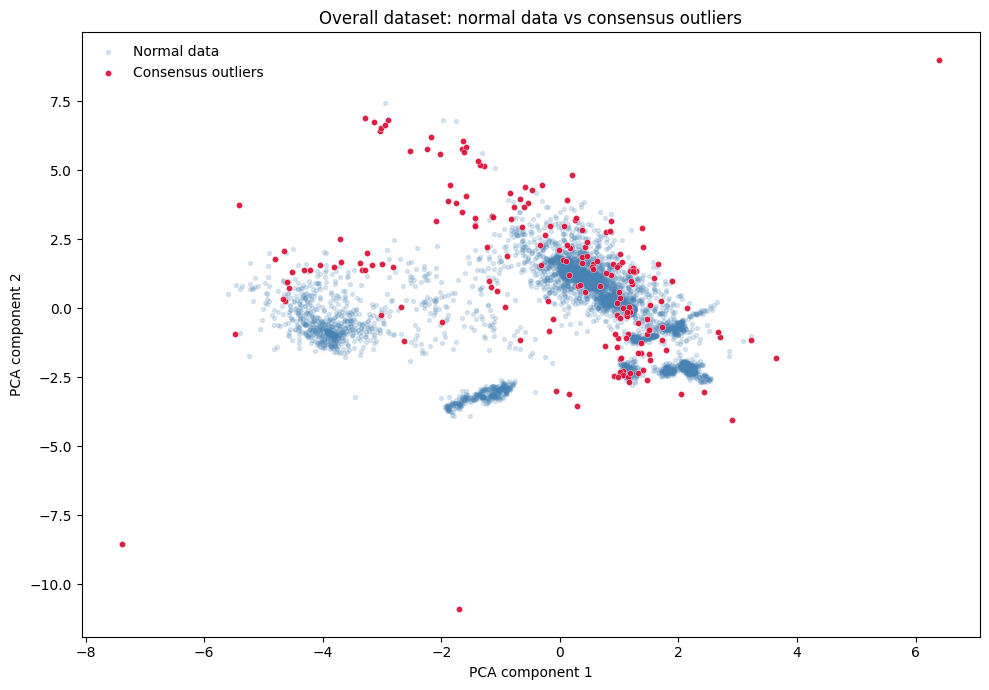

Rows flagged by at least one method: 4759
Rows flagged by at least two methods: 185


In [10]:
overall_report, overall_summary = build_outlier_report(
    df,
    subset_name='overall dataset',
    full_frame=df,
)

display_outlier_report(overall_report, overall_summary, 'Overall dataset outlier analysis')
plot_outliers_vs_normal(df, overall_report, 'Overall dataset: normal data vs consensus outliers')

print('Rows flagged by at least one method:', int((overall_report[[column for column in overall_report.columns if column.endswith("_flag")]].sum(axis=1) > 0).sum()))
print('Rows flagged by at least two methods:', int(overall_report['consensus_flag'].sum()))


=== Class-wise outlier analysis: sitting ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,507,1.001
1,LOF,507,1.001
2,Mahalanobis,507,1.001


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
29951,29951,wallace,sitting,3,True,1.000000,5.398587,1410.598252
29953,29953,wallace,sitting,3,True,1.000000,5.560041,1580.110985
29963,29963,wallace,sitting,3,True,1.000000,4.007438,1230.413957
29952,29952,wallace,sitting,3,True,1.000000,4.139949,1463.061041
44930,44930,jose_carlos,sitting,3,True,1.000000,6.559877,298.351821
29936,29936,wallace,sitting,3,True,1.000000,4.285458,1899.945767
29935,29935,wallace,sitting,3,True,1.000000,4.281650,1896.254584
29950,29950,wallace,sitting,3,True,1.000000,4.258613,1793.235838
29933,29933,wallace,sitting,3,True,1.000000,4.043670,1477.146328
44926,44926,jose_carlos,sitting,3,True,0.999999,6.452191,217.329015


Consensus rows flagged by at least 2 methods: 273


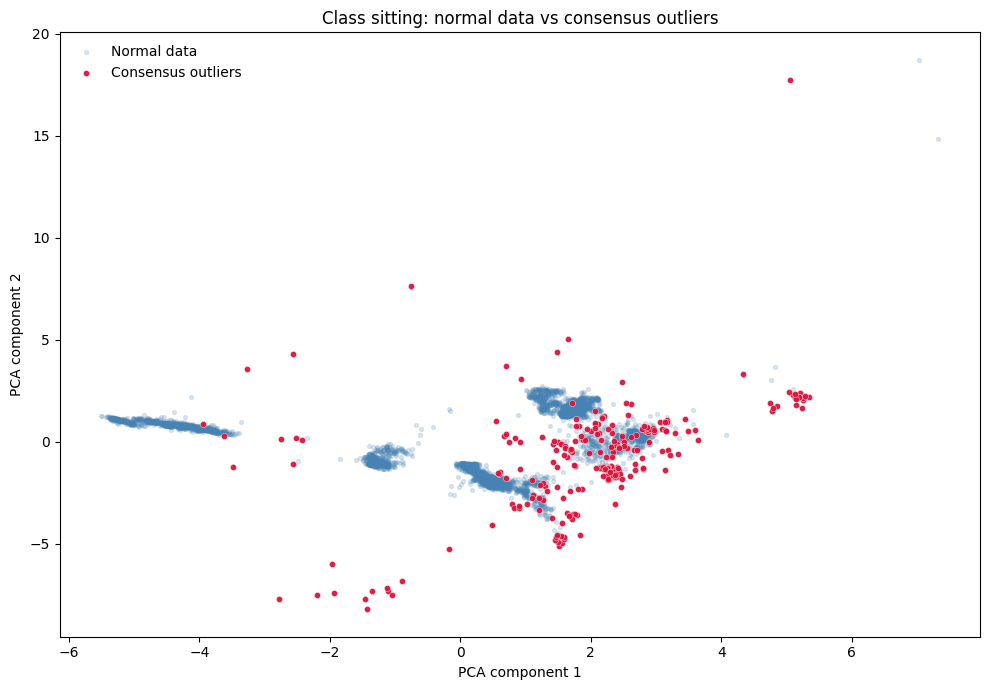


=== Class-wise outlier analysis: sittingdown ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,119,1.006
1,LOF,119,1.006
2,Mahalanobis,119,1.006


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
8590,59221,wallace,sittingdown,3,True,1.000000,20.498580,1146.023194
8375,59006,wallace,sittingdown,3,True,0.998061,7.194414,307.491293
3004,53635,debora,sittingdown,3,True,0.986820,6.184071,965.703110
8794,59425,wallace,sittingdown,2,True,0.999992,1.956023,221.585446
9625,60256,wallace,sittingdown,2,True,0.999876,1.240293,139.522575
9223,59854,wallace,sittingdown,2,True,0.999860,1.300279,136.110102
9184,59815,wallace,sittingdown,2,True,0.999786,1.175911,118.031868
9236,59867,wallace,sittingdown,2,True,0.999763,1.189288,124.358799
9372,60003,wallace,sittingdown,2,True,0.999678,1.192475,131.364767
10514,61145,wallace,sittingdown,2,True,0.999585,2.786060,57.038376


Consensus rows flagged by at least 2 methods: 50


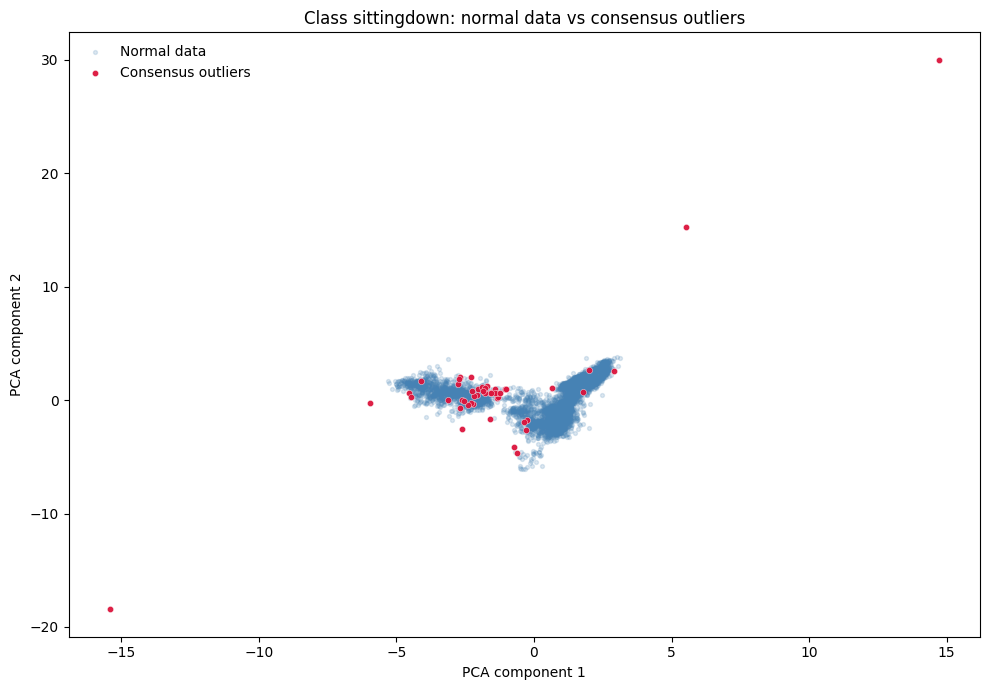


=== Class-wise outlier analysis: standing ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,474,1.001
1,LOF,474,1.001
2,Mahalanobis,474,1.001


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
40516,102974,wallace,standing,3,True,0.999994,7.177379,618.973127
40514,102972,wallace,standing,3,True,0.999991,6.439558,606.546489
40515,102973,wallace,standing,3,True,0.999990,7.884686,592.385859
40517,102975,wallace,standing,3,True,0.999990,4.499946,580.787955
40518,102976,wallace,standing,3,True,0.999985,7.579880,526.062497
40519,102977,wallace,standing,3,True,0.999977,3.664038,527.799198
37025,99483,wallace,standing,3,True,0.999965,10.429220,2020.416683
40513,102971,wallace,standing,3,True,0.999965,4.668326,1758.592662
37030,99488,wallace,standing,3,True,0.999961,8.599223,2099.157758
37029,99487,wallace,standing,3,True,0.999959,9.180604,2095.384070


Consensus rows flagged by at least 2 methods: 221


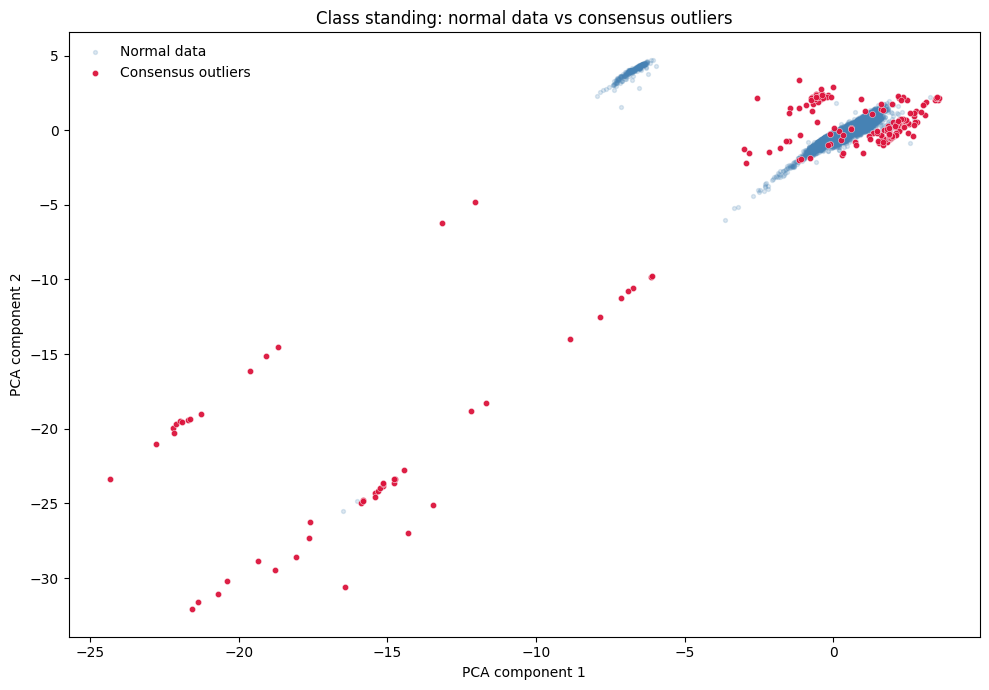


=== Class-wise outlier analysis: standingup ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,125,1.007
1,LOF,125,1.007
2,Mahalanobis,125,1.007


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
5435,115263,katia,standingup,3,True,1.000000,3.841114,207.952782
5436,115264,katia,standingup,3,True,1.000000,2.381780,212.456310
5434,115262,katia,standingup,3,True,0.999999,2.804719,104.167647
4478,114306,katia,standingup,3,True,0.999679,3.465267,327.031129
12253,122081,jose_carlos,standingup,3,True,0.999610,2.425644,66.936923
5746,115574,katia,standingup,2,True,1.000000,1.358698,70.059663
6371,116199,katia,standingup,2,True,1.000000,1.201540,52.282515
6374,116202,katia,standingup,2,True,0.999999,1.213307,53.309093
5749,115577,katia,standingup,2,True,0.999999,1.251668,60.666006
6372,116200,katia,standingup,2,True,0.999999,1.223606,54.952753


Consensus rows flagged by at least 2 methods: 45


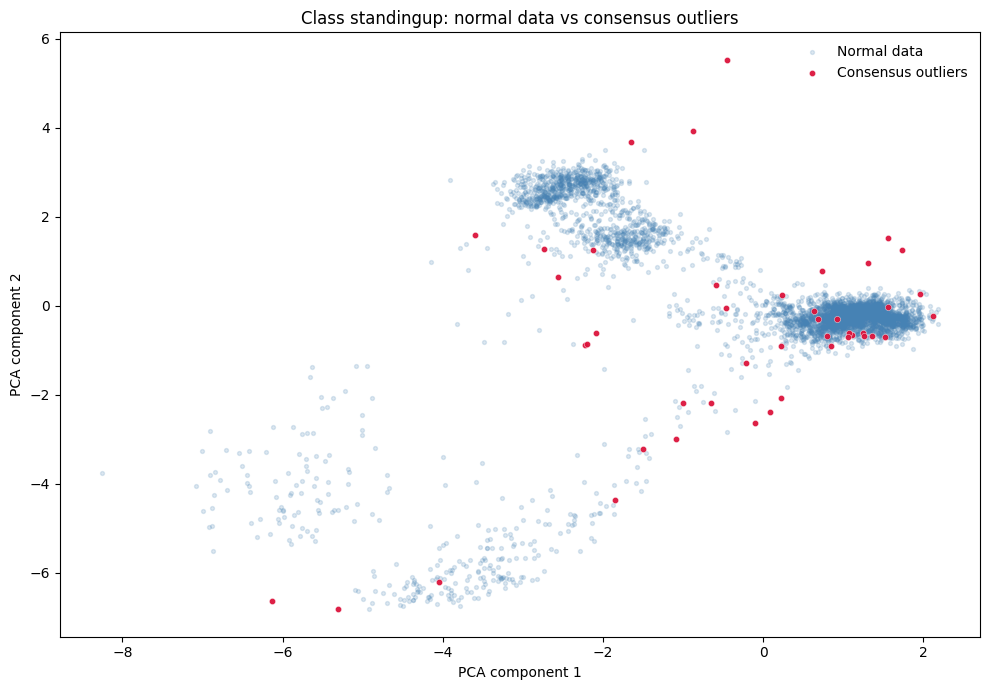


=== Class-wise outlier analysis: walking ===


,method,flagged_rows,flag_rate_%
0,ClassificationBased,434,1.0
1,LOF,434,1.0
2,Mahalanobis,434,1.0


,row_index,user,class,consensus_count,consensus_flag,ClassificationBased_score,LOF_score,Mahalanobis_score
29493,151736,wallace,walking,3,True,1.000000,3.226201,160.003567
42421,164664,jose_carlos,walking,3,True,1.000000,4.411391,429.767390
29492,151735,wallace,walking,3,True,1.000000,4.291714,113.368623
41965,164208,jose_carlos,walking,3,True,0.999999,1.935297,62.320697
42798,165041,jose_carlos,walking,3,True,0.999999,2.372673,60.781403
42644,164887,jose_carlos,walking,3,True,0.999995,1.728541,52.178962
42420,164663,jose_carlos,walking,3,True,0.999991,2.070451,76.516560
42651,164894,jose_carlos,walking,3,True,0.999883,1.857406,50.269264
41808,164051,jose_carlos,walking,3,True,0.999868,5.832798,98.004892
42972,165215,jose_carlos,walking,3,True,0.998865,1.806812,56.384990


Consensus rows flagged by at least 2 methods: 134


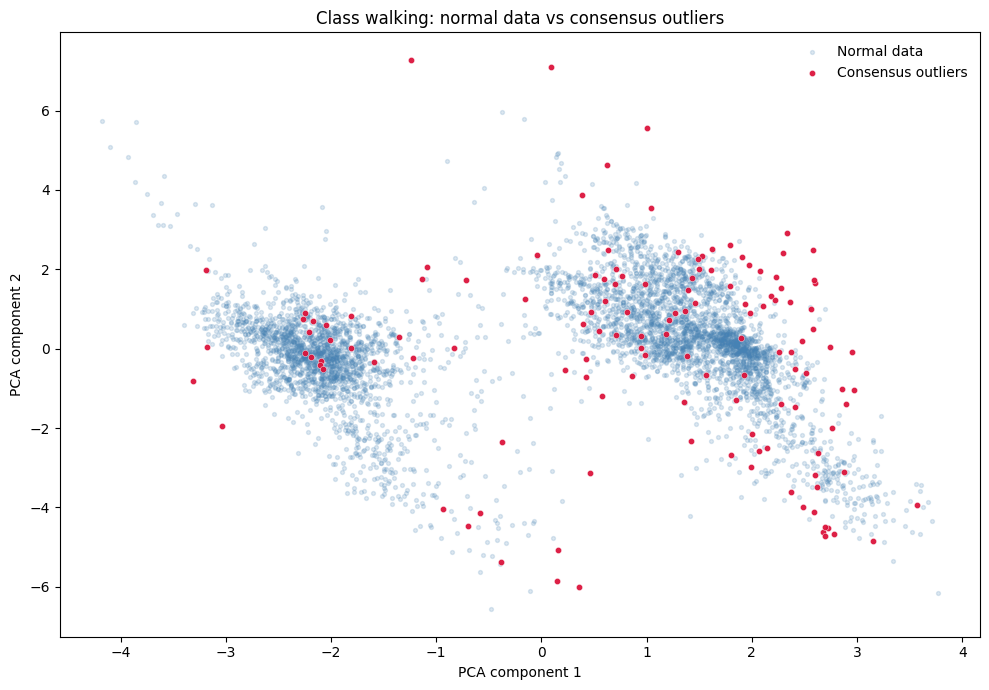

,class,rows,consensus_flagged_rows,any_method_flagged_rows
0,sitting,50631,273,1205
1,standing,47370,221,1137
2,walking,43390,134,1153
3,sittingdown,11827,50,304
4,standingup,12415,45,325


In [11]:
classwise_reports = {}
classwise_summaries = {}
classwise_consensus = []

for class_label in class_names:
    subset = df[df[class_col].astype(str) == class_label].copy()
    report, summary = build_outlier_report(
        subset,
        subset_name=f'class: {class_label}',
        full_frame=df,
        class_label=class_label,
    )
    classwise_reports[class_label] = report
    classwise_summaries[class_label] = summary
    classwise_consensus.append({
        'class': class_label,
        'rows': len(report),
        'consensus_flagged_rows': int(report['consensus_flag'].sum()),
        'any_method_flagged_rows': int((report[[column for column in report.columns if column.endswith("_flag")]].sum(axis=1) > 0).sum()),
    })
    display_outlier_report(report, summary, f'Class-wise outlier analysis: {class_label}')
    plot_outliers_vs_normal(subset, report, f'Class {class_label}: normal data vs consensus outliers')

classwise_overview = pd.DataFrame(classwise_consensus).sort_values('consensus_flagged_rows', ascending=False).reset_index(drop=True)
display(classwise_overview)